<a href="https://colab.research.google.com/github/Andre-Victor-Vasconcelos/Redes-Neurais-Artificiais---Francisco-de-Assis-Boldt/blob/main/Classificar_o_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import gzip
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# URLs do repositório confiável para o MNIST original (mirror CVDF/Google)
base_url = "https://storage.googleapis.com/cvdf-datasets/mnist/"
arquivos = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images": "t10k-images-idx3-ubyte.gz",
    "test_labels": "t10k-labels-idx1-ubyte.gz"
}

# Baixando os arquivos caso não existam no ambiente
print("Verificando e baixando os arquivos originais do MNIST...")
for nome, arquivo in arquivos.items():
    if not os.path.exists(arquivo):
        print(f"Baixando {arquivo}...")
        urllib.request.urlretrieve(base_url + arquivo, arquivo)
print("Download concluído!")

Verificando e baixando os arquivos originais do MNIST...
Baixando train-images-idx3-ubyte.gz...
Baixando train-labels-idx1-ubyte.gz...
Baixando t10k-images-idx3-ubyte.gz...
Baixando t10k-labels-idx1-ubyte.gz...
Download concluído!


In [2]:
def ler_imagens_idx(caminho_arquivo):
    """Lê as imagens do formato binário IDX original e adapta para CNN."""
    with gzip.open(caminho_arquivo, 'rb') as f:
        # Pula os 16 bytes do cabeçalho e lê os pixels
        dados = np.frombuffer(f.read(), dtype=np.uint8, offset=16)

    # O dataset possui imagens de 28x28.
    # Para uma CNN, precisamos adicionar o canal de cor (1 para escala de cinza)
    imagens_formatadas = dados.reshape(-1, 28, 28, 1)

    # Pré-processamento: Normalização dos pixels [0, 255] para [0.0, 1.0]
    return imagens_formatadas.astype(np.float32) / 255.0

def ler_labels_idx(caminho_arquivo):
    """Lê os rótulos do formato binário IDX original."""
    with gzip.open(caminho_arquivo, 'rb') as f:
        # Pula os 8 bytes do cabeçalho
        labels = np.frombuffer(f.read(), dtype=np.uint8, offset=8)
    return labels

# Extraindo e pré-processando
X_train = ler_imagens_idx(arquivos["train_images"])
y_train = ler_labels_idx(arquivos["train_labels"])

X_test = ler_imagens_idx(arquivos["test_images"])
y_test = ler_labels_idx(arquivos["test_labels"])

print(f"Formato dos dados de treino: {X_train.shape}")
print(f"Formato dos rótulos de treino: {y_train.shape}")
print(f"Formato dos dados de teste: {X_test.shape}")

Formato dos dados de treino: (60000, 28, 28, 1)
Formato dos rótulos de treino: (60000,)
Formato dos dados de teste: (10000, 28, 28, 1)


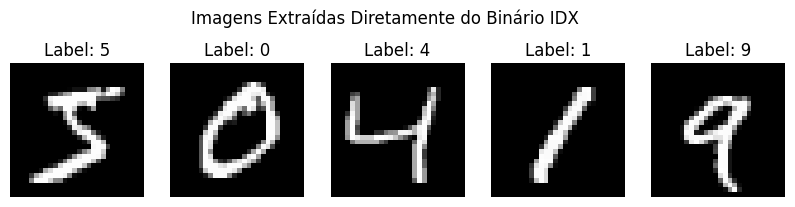

In [3]:
# Mostrando 5 imagens extraídas manualmente
plt.figure(figsize=(10, 2))
for i in range(5):
    plt.subplot(1, 5, i+1)
    # Precisamos tirar o último canal (.reshape) apenas para a visualização
    plt.imshow(X_train[i].reshape(28, 28), cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.suptitle("Imagens Extraídas Diretamente do Binário IDX", y=1.1)
plt.show()

In [6]:
# Construindo a Arquitetura da CNN
model = Sequential([
    # 1ª Camada Convolucional + MaxPooling
    Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D(pool_size=(2, 2)),

    # 2ª Camada Convolucional + MaxPooling
    Conv2D(64, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),

    # Achatar (Flatten) para conectar com a rede densa
    Flatten(),

    # Camada Oculta (MLP)
    Dense(128, activation='relu'),
    Dropout(0.5), # Evita overfitting

    # Camada de Saída (10 classes: números de 0 a 9)
    Dense(10, activation='softmax')
])

# Compilando o modelo
# Usamos sparse_categorical_crossentropy porque não fizemos o one-hot encoding nos labels manuais
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

# Treinando a rede
print("\nIniciando o treinamento da CNN...")
history = model.fit(X_train, y_train,
                    epochs=5,
                    batch_size=64,
                    validation_split=0.1) # Usa 10% do treino para validação

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)


Iniciando o treinamento da CNN...
Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 60s 65ms/step - accuracy: 0.9218 - loss: 0.2598 - val_accuracy: 0.9845 - val_loss: 0.0554
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 80s 64ms/step - accuracy: 0.9733 - loss: 0.0921 - val_accuracy: 0.9867 - val_loss: 0.0402
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 80s 62ms/step - accuracy: 0.9795 - loss: 0.0689 - val_accuracy: 0.9887 - val_loss: 0.0373
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 50s 59ms/step - accuracy: 0.9841 - loss: 0.0540 - val_accuracy: 0.9902 - val_loss: 0.0351
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 89s 67ms/step - accuracy: 0.9849 - loss: 0.0472 - val_accuracy: 0.9897 - val_loss: 0.0382



Acurácia da CNN nos dados de teste brutos: 99.01%


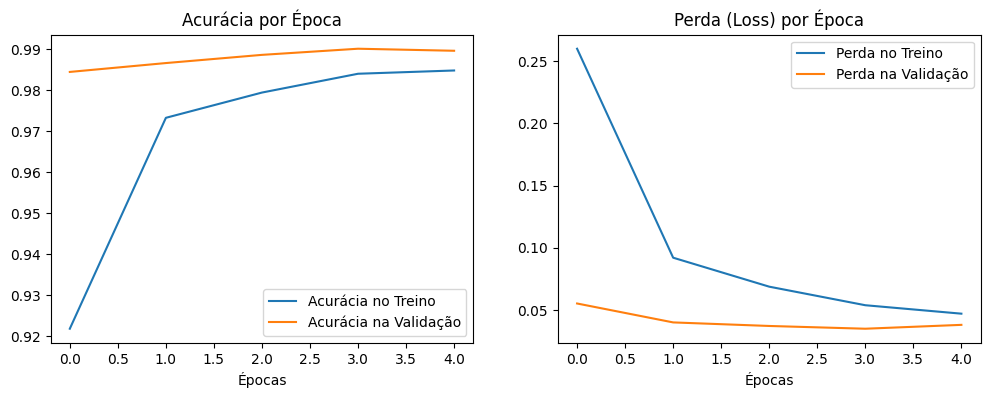

In [7]:
# Avaliando com a base de teste baixada
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nAcurácia da CNN nos dados de teste brutos: {test_acc*100:.2f}%")

# Gráfico de evolução do treinamento
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Acurácia no Treino')
plt.plot(history.history['val_accuracy'], label='Acurácia na Validação')
plt.title('Acurácia por Época')
plt.xlabel('Épocas')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Perda no Treino')
plt.plot(history.history['val_loss'], label='Perda na Validação')
plt.title('Perda (Loss) por Época')
plt.xlabel('Épocas')
plt.legend()

plt.show()